
=== KGC  [GN2Tracks_KGC_20261119-T212322, epoch=049] ===
  N señal = 35,380   N fondo = 44,019   AUC = 0.8742
  eff_sig = 60% -> 1-eff_bg = 0.9097   rechazo =     11.1   (corte p_sig > 0.7217)
  eff_sig = 70% -> 1-eff_bg = 0.8591   rechazo =      7.1   (corte p_sig > 0.6262)
  eff_sig = 80% -> 1-eff_bg = 0.7819   rechazo =      4.6   (corte p_sig > 0.4994)
  eff_sig = 90% -> 1-eff_bg = 0.6420   rechazo =      2.8   (corte p_sig > 0.3257)

=== KG  [GN2Tracks_KG_20261105-T131007, epoch=049] ===
  N señal = 35,380   N fondo = 44,019   AUC = 0.8820
  eff_sig = 60% -> 1-eff_bg = 0.9182   rechazo =     12.2   (corte p_sig > 0.7302)
  eff_sig = 70% -> 1-eff_bg = 0.8701   rechazo =      7.7   (corte p_sig > 0.6310)
  eff_sig = 80% -> 1-eff_bg = 0.7991   rechazo =      5.0   (corte p_sig > 0.5061)
  eff_sig = 90% -> 1-eff_bg = 0.6621   rechazo =      3.0   (corte p_sig > 0.3257)

=== K  [GN2Tracks_K_20261119-T221831, epoch=049] ===
  N señal = 35,380   N fondo = 44,019   AUC = 0.8824
  eff_sig

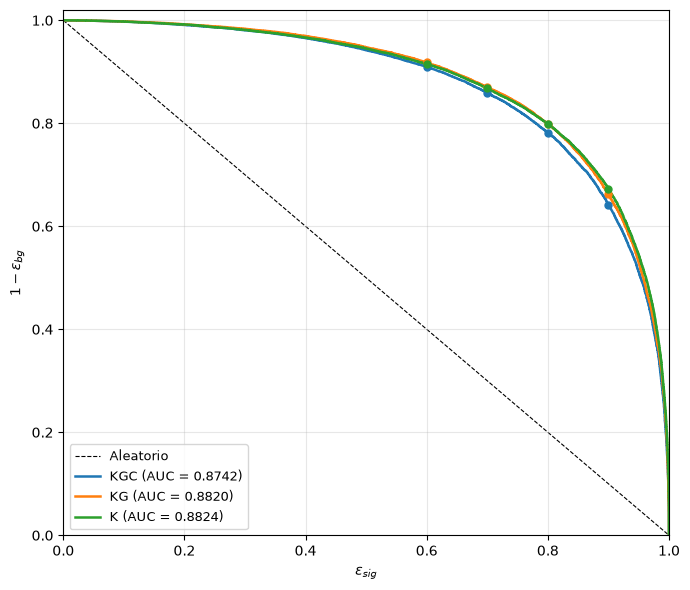


modelo       AUC    1-eb@60%    1-eb@70%    1-eb@80%    1-eb@90%
---------------------------------------------------------------
K      0.8824      0.9150      0.8677      0.7989      0.6728
KG     0.8820      0.9182      0.8701      0.7991      0.6621
KGC    0.8742      0.9097      0.8591      0.7819      0.6420

Guardado: /home/usuario/VSCode/diHiggs-Project/OutTrainings/Roc_comparison.png


In [1]:
"""Comparacion de curvas ROC (1 - eff_bg vs eff_sig) de varios entrenamientos de `salt test`."""

from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

# --- Ajustar ---
OUT_TRAINING_PATH = Path("/home/usuario/VSCode/diHiggs-Project/OutTrainings")

# (carpeta del entrenamiento, epoca, label de la curva)
GNNs = [
    ("GN2Tracks_KGC_20261119-T212322", "049", "KGC"),
    ("GN2Tracks_KG_20261105-T131007", "049", "KG"),
    ("GN2Tracks_K_20261119-T221831", "049", "K"),
]

OBJ       = "jets"          # global_object del entrenamiento
SIG_CLASS = "hadtaujets"    # el score se llama <modelo>_p<clase>
WPS       = [0.6, 0.7, 0.8, 0.9]
SAVE_AS   = OUT_TRAINING_PATH / "Roc_comparison.png"

trapezoid = getattr(np, "trapezoid", None) or np.trapz  # numpy < 2.0


def find_test_file(run_dir, epoch, sample):
    matches = sorted((run_dir / "ckpts").glob(f"epoch={epoch}-*__test_{sample}*.h5"))
    if not matches:
        raise FileNotFoundError(f"No hay test '{sample}' para epoch={epoch} en {run_dir / 'ckpts'}")
    return matches[0]


def load(fname):
    with h5py.File(fname, "r") as h:
        d = h[OBJ]
        score = next((n for n in d.dtype.names if n.endswith(f"_p{SIG_CLASS}")), None)
        if score is None:
            raise KeyError(f"No hay '*_p{SIG_CLASS}' en {fname.name}. Campos: {d.dtype.names}")
        return d.fields(score)[:].astype(np.float64)


def roc(s_sig, s_bkg):
    """Ordena todos los scores de mayor a menor y acumula."""
    scores = np.concatenate([s_sig, s_bkg])
    is_sig = np.concatenate([np.ones_like(s_sig), np.zeros_like(s_bkg)])
    order  = np.argsort(-scores, kind="stable")
    e_sig  = np.concatenate([[0], np.cumsum(is_sig[order]) / len(s_sig)])
    e_bkg  = np.concatenate([[0], np.cumsum(1 - is_sig[order]) / len(s_bkg)])
    return e_sig, e_bkg, trapezoid(1 - e_bkg, e_sig)


fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [1, 0], "k--", lw=0.8, label="Aleatorio", zorder=1)

resumen = []

for carpeta, epoch, label in GNNs:
    run_dir = OUT_TRAINING_PATH / carpeta

    s_sig = load(find_test_file(run_dir, epoch, "signal"))
    s_bkg = load(find_test_file(run_dir, epoch, "background"))
    e_sig, e_bkg, auc = roc(s_sig, s_bkg)

    linea, = ax.plot(e_sig, 1 - e_bkg, lw=1.8, label=f"{label} (AUC = {auc:.4f})")
    color  = linea.get_color()

    print(f"\n=== {label}  [{carpeta}, epoch={epoch}] ===")
    print(f"  N señal = {len(s_sig):,}   N fondo = {len(s_bkg):,}   AUC = {auc:.4f}")

    fila = {"label": label, "auc": auc}
    for wp in WPS:
        cut = np.percentile(s_sig, np.clip(100 * (1 - wp), 0, 100))
        eb  = np.mean(s_bkg > cut)
        rechazo = np.inf if eb == 0 else 1.0 / eb
        print(f"  eff_sig = {wp:.0%} -> 1-eff_bg = {1 - eb:.4f}   "
              f"rechazo = {rechazo:>8.1f}   (corte p_sig > {cut:.4f})")
        ax.plot(wp, 1 - eb, "o", color=color, ms=5, zorder=3)
        fila[wp] = 1 - eb
    resumen.append(fila)

ax.set_xlabel(r"$\epsilon_{sig}$")
ax.set_ylabel(r"$1 - \epsilon_{bg}$")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)
ax.legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.savefig(SAVE_AS, dpi=300)
plt.show()

# --- tabla comparativa ---
w = max(len(f["label"]) for f in resumen)
ancho = w + 12 + 12 * len(WPS)
print("\n" + "=" * ancho)
print(f"{'modelo':<{w}}  {'AUC':>8}" + "".join(f"  {f'1-eb@{wp:.0%}':>10}" for wp in WPS))
print("-" * ancho)
for f in sorted(resumen, key=lambda r: -r["auc"]):
    print(f"{f['label']:<{w}}  {f['auc']:>8.4f}" + "".join(f"  {f[wp]:>10.4f}" for wp in WPS))
print("=" * ancho)
print(f"\nGuardado: {SAVE_AS}")